# Navier–Stokes in SymPy and Lean 4

**Definitions, symbolic checks, and cell tracking in a known flow**

The repository [openai/NavierStokesAndEuler](https://github.com/openai/NavierStokesAndEuler) states the
Clay Navier–Stokes problem in **Lean 4 + Mathlib**. Its README says the `NavierStokes/` tree proves
Clay alternatives **(C)** (breakdown on $\mathbb{R}^3$) and **(D)** (breakdown on the torus
$\mathbb{R}^3/\mathbb{Z}^3$).

This notebook does three things:

1. **Reads the Lean definitions** from a local clone and rebuilds each one in SymPy, so every symbol
   in the Lean file has a hand-checkable formula next to it.
2. **Checks** the lemmas and classical identities (divergence = trace, linearity, exact solutions,
   the energy identity, scaling, 2D vs 3D vortex stretching).
3. **Uses the equations numerically.** Synthetic "cells" are imaged and tracked in a flow whose true
   velocity is known exactly. Then the Lean `div_free` field is used as a physical constraint to denoise
   a measured velocity field.

> **Check ≠ proof.** SymPy shows that an identity simplifies to 0, or that one specific flow satisfies
> the equation. Lean's kernel checks a proof **for every function in the class**. Nothing in this
> notebook tests the breakdown theorems, which are existence statements about specially built initial data.
> Only `lake build` in the clone checks those (§10). **It was run on 2026-10-04**: the full build
> (11,424 jobs) completed with 0 errors. Both breakdown theorems depend only on Lean's three standard
> axioms, and the solution's definitions match the challenge file line for line. §10 re-checks this
> live when Lean is installed. That is a machine-checked proof of the *formal statements*. Whether
> they faithfully capture Clay's English problem is still a human judgment about the definitions,
> which is what §1–§7 help you make.

Everything numerical is **synthetic**, with fixed seeds. No laboratory data is used and no lab
affiliation is implied. Module: [`dgs/navier_stokes_lean_companion.py`](../dgs/navier_stokes_lean_companion.py)

**References (IEEE)**
1. C. L. Fefferman, "Existence and smoothness of the Navier–Stokes equation," in *The Millennium Prize Problems*, J. Carlson, A. Jaffe, and A. Wiles, Eds. Providence, RI, USA: Clay Math. Inst./AMS, 2006, pp. 57–67.
2. The mathlib Community, "The Lean mathematical library," in *Proc. 9th ACM SIGPLAN Int. Conf. Certified Programs and Proofs (CPP)*, 2020, pp. 367–381.
3. G. I. Taylor and A. E. Green, "Mechanism of the production of small eddies from large ones," *Proc. R. Soc. Lond. A*, vol. 158, no. 895, pp. 499–521, 1937.
4. A. J. Chorin and J. E. Marsden, *A Mathematical Introduction to Fluid Mechanics*, 3rd ed. New York, NY, USA: Springer, 1993.
5. K. Goda, K. K. Tsia, and B. Jalali, "Serial time-encoded amplified imaging for real-time observation of fast dynamic phenomena," *Nature*, vol. 458, pp. 1145–1149, 2009.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
sp.init_printing()
from dgs import navier_stokes_lean_companion as ns
from dgs.navier_stokes_lean_companion import x, y, z, t, nu, lam

# 1. What is in the Lean repository

`repo_inventory()` counts Lean files, lines and `sorry` placeholders. In Lean, `sorry` means
"assume this without proof." The challenge file is the *statement*: its two main theorems end in
`sorry` on purpose, and the solution tree has to fill them in. A count of 0 in the proof trees means no
step is *visibly* skipped. It is **not** a verification: only compiling with `lake build` makes the
kernel check every step, and only a statement comparison shows the proved theorem is the one in the
challenge file.

In [2]:
inv = ns.repo_inventory()
if inv is None:
    print("Clone not found. Run (from the folder that contains this repo):")
    print("  git clone --depth 1 https://github.com/openai/NavierStokesAndEuler")
else:
    display(pd.DataFrame({k: v for k, v in inv.items() if isinstance(v, dict)}).T)
    print("challenge-file sorry tactics:", inv["challenge_sorry_tactics"])
    print("toolchain:", inv["toolchain"])

,lean_files,lines,sorry
NavierStokes,816,429279,0
Euler,1839,211578,0


challenge-file sorry tactics: 2
toolchain: leanprover/lean4:v4.34.0-rc2


## 1.1 The definitions, quoted from the Lean source

The cells below print the declarations directly from `ComparatorChallenges/NavierStokes.lean`, so
what you read is exactly what Lean checks.

In [3]:
def show_lean(name):
    s = ns.lean_statement(name)
    display(Markdown("```lean\n" + (s or f"-- {name}: clone not found") + "\n```"))

for name in ("divergence", "divergence_add", "IsOnePeriodic", "InitialVelocityCondition"):
    show_lean(name)

```lean
def divergence (v : ℝ^n → ℝ^n) (x : ℝ^n) : ℝ := (fderiv ℝ v x).trace ℝ (ℝ^n)
```

```lean
/-- Divergence is additive at points where both vector fields are differentiable. -/
theorem divergence_add {v w : ℝ^n → ℝ^n} {x : ℝ^n}
    (hv : DifferentiableAt ℝ v x) (hw : DifferentiableAt ℝ w x) :
    ∇⬝ (fun y => v y + w y) x = ∇⬝ v x + ∇⬝ w x := by
  rw [divergence, fderiv_fun_add hv hw]
  exact map_add _ _ _
```

```lean
/--
A function $f : \mathbb{R}^n \to \alpha$ is 1-periodic if it is periodic in each
coordinate with period $1$, i.e. $f(x + e_i) = f(x)$ for each unit vector $e_i$.
This captures functions on the $n$-torus $\mathbb{R}^n/\mathbb{Z}^n$.
-/
def IsOnePeriodic {α : Sort*} (f : ℝ^n → α) : Prop :=
  ∀ x i, f (x + EuclideanSpace.single i 1) = f x
```

```lean
/--
Basic conditions on initial velocity field for the Navier-Stokes equations
in $n$-dimensional space.

The initial velocity must be:
- Divergence-free (incompressibility condition: $\nabla \cdot u_0 = 0$)
- Smooth ($C^\infty$)

These conditions apply regardless of spatial dimension.
-/
structure InitialVelocityCondition (u₀ : ℝ^n → ℝ^n) : Prop where
  /-- The initial velocity field is divergence-free (equation 2).
      This is the incompressibility constraint for the fluid. -/
  div_free : ∀ x, ∇⬝ u₀ x = 0
  /-- The initial velocity field is smooth ($C^\infty$ in all variables). -/
  smooth : ContDiff ℝ ∞ u₀
```

In [4]:
for name in ("NavierStokesExistenceAndSmoothness", "navier_stokes_breakdown_R3"):
    show_lean(name)

```lean
/--
A solution (v, p) to the Navier-Stokes equations in n-dimensional space
with viscosity $\nu$, initial velocity $u_0$, and external force $f$.

This structure captures the core requirements for a solution:
1. The velocity and pressure satisfy the Navier-Stokes PDE (equation 1)
2. The velocity remains divergence-free for all time (equation 2)
3. The initial condition is satisfied (equation 3)
4. The solution is smooth ($C^\infty$) for all time $t \ge 0$ (equations 6, 11)
-/
structure NavierStokesExistenceAndSmoothness
    (nu : ℝ) (u₀ : ℝ^n → ℝ^n) (f : ℝ^n → ℝ → ℝ^n)
    (v : ℝ^n → ℝ → ℝ^n) (p : ℝ^n → ℝ → ℝ) : Prop where
  /-- The Navier-Stokes equation (equation 1):
  $\partial v/\partial t + (v \cdot \nabla)v = \nu\Delta v - \nabla p + f$. -/
  navier_stokes : ∀ x, ∀ t ≥ 0,
    derivWithin (v x ·) (Set.Ici 0) t + fderiv ℝ (v · t) x (v x t) =
      nu • Δ (v · t) x - gradient (p · t) x + f x t
  /-- Incompressibility constraint (equation 2): $\nabla \cdot v = 0$ for all
  $x$ and $t \ge 0$. -/
  div_free : ∀ x, ∀ t ≥ 0, ∇⬝ (v · t) x = 0
  /-- Initial condition (equation 3): $v(x,0) = u_0(x)$ for all $x$. -/
  initial_condition : ∀ x, v x 0 = u₀ x
  /-- The velocity field is smooth ($C^\infty$) on $\mathbb{R}^n \times [0,\infty)$
  (conditions 6, 11). -/
  velocity_smooth : ContDiffOn ℝ ∞ (↿v) (Set.univ ×ˢ Set.Ici 0)
  /-- The pressure field is smooth ($C^\infty$) on $\mathbb{R}^n \times [0,\infty)$
  (conditions 6, 11). -/
  pressure_smooth : ContDiffOn ℝ ∞ (↿p) (Set.univ ×ˢ Set.Ici 0)
```

```lean
/-- (C) Breakdown of Navier–Stokes solutions on ℝ³. -/
theorem navier_stokes_breakdown_R3 (nu : ℝ) (hnu : nu > 0) :
    ∃ (u₀ : ℝ³ → ℝ³) (f : ℝ³ → ℝ → ℝ³),
    InitialVelocityConditionDecay u₀ ∧ ForceConditionDecay f ∧
    ¬ (∃ v p, NavierStokesExistenceAndSmoothnessRn nu u₀ f v p) := by
  sorry
```

### Reading the main theorem in plain language

`navier_stokes_breakdown_R3 nu hnu` says: for every viscosity $\nu > 0$ **there exist** smooth,
rapidly decaying, divergence-free initial data $u_0$ and a smooth, decaying force $f$ such that **no**
pair $(v, p)$ satisfies all of the following:

* the PDE $\partial_t v + (\nabla v)\,v = \nu\Delta v - \nabla p + f$ for all $t \ge 0$;
* `div_free`, the initial condition, and $C^\infty$ smoothness on $\mathbb{R}^3\times[0,\infty)$;
* finite, uniformly bounded energy.

The logical shape is $\exists\,u_0, f.\;\neg\exists\,v, p.\;\text{Solution}(v,p)$. To prove it you have to
**build** specific data and show that every candidate solution fails. No finite set of examples can do
that, so this notebook cannot reach it. What we *can* do is make sure every definition it depends on
means what we think it means.

# 2. Divergence is the trace of the Jacobian

Lean defines `divergence v x := (fderiv ℝ v x).trace`. `fderiv ℝ v x` is the **total derivative**, the
linear map $h \mapsto J(x)\,h$ with $J_{ij} = \partial v_i/\partial x_j$. Its trace is
$\sum_i \partial v_i/\partial x_i$, the textbook divergence.

### Hand proof of `divergence_add`
$$\nabla\!\cdot(v+w) = \operatorname{tr} D(v+w) \overset{(a)}{=} \operatorname{tr}(Dv + Dw) \overset{(b)}{=} \operatorname{tr} Dv + \operatorname{tr} Dw .$$
(a) The derivative of a sum is the sum of the derivatives, when both are differentiable. In Lean
this is `fderiv_fun_add hv hw`. (b) Trace is linear: `map_add`. The Lean proof is exactly these two
steps: `rw [divergence, fderiv_fun_add hv hw]; exact map_add _ _ _`.

The hypotheses `hv`, `hw` matter. Lean's `fderiv` returns 0 (a "junk value") where $v$ is not
differentiable, and the lemma would be false without them. SymPy's undefined `Function`s are
silently assumed smooth, so the SymPy check below can't see that subtlety.

In [5]:
v = ns._generic_field("v")
display(Math(r"J = " + sp.latex(ns.jacobian(v))))
display(Math(r"\nabla\cdot v = \operatorname{tr}J = " + sp.latex(ns.divergence(v))))
pd.DataFrame({"lemma": list(ns.divergence_lemmas()), "residual (must be 0)": [str(r) for r in ns.divergence_lemmas().values()]})

<IPython.core.display.Math object>

<IPython.core.display.Math object>

,lemma,residual (must be 0)
0,divergence_zero,0
1,divergence_const,0
2,divergence_add,0
3,divergence_smul,0


**Why define it as a trace?** A trace doesn't depend on the basis, since
$\operatorname{tr}(QJQ^{-1}) = \operatorname{tr}J$. So the divergence is a geometric quantity (the rate of
change of volume, $\tfrac{d}{dt}\ln\det$ of the flow map) and not an artifact of the coordinates. The
check below uses a rotation:

In [6]:
print("tr(Q J Q^T) - tr(J) =", ns.trace_is_coordinate_free())
print("(fderiv v)(v) - (v.grad)v =", list(ns.convective_matches_textbook()))

tr(Q J Q^T) - tr(J) = 0
(fderiv v)(v) - (v.grad)v = [0, 0, 0]


The second line is the **convective term**. Lean writes it as `fderiv ℝ (v · t) x (v x t)`, the
Jacobian applied to the velocity, $J v$. Componentwise this is $\sum_j v_j\,\partial_j v_i = (v\cdot\nabla)v$,
the same nonlinearity that makes the problem hard.

**ML link.** $J v$ is a matrix–vector product whose matrix depends on the vector. That is the
same "input-dependent weight" structure as attention ($\mathrm{softmax}(QK^\top)V$, where $Q$, $K$, $V$
all come from the input). Neural operators such as the FNO learn the solution map of this PDE.

# 3. Exact solutions: checking every field of the Lean structure

Two classical flows. With wavenumber $k = 2\pi$ both are 1-periodic, which is the torus convention of
`IsOnePeriodic`:

* **Taylor–Green** [3]: $v = e^{-2\nu k^2 t}(\sin kx\cos ky,\,-\cos kx\sin ky,\,0)$ with no force. It decays.
* **ABC (Arnold–Beltrami–Childress)**: a Beltrami flow ($\nabla\times v = k v$). It is steady if
  driven by $f = \nu k^2 v$, with the Bernoulli pressure $p = -|v|^2/2$.

For each we compute the `navier_stokes` residual (it must be the zero vector), `div_free`, and
`IsOnePeriodic`.

In [7]:
rows = []
for name, flow in (("Taylor-Green", ns.taylor_green), ("ABC", ns.abc_flow)):
    v, p, f = flow()
    rows.append({"flow": name, "NS residual": str(list(ns.ns_residual(v, p, f))),
                 "div v": str(ns.divergence(v)), "IsOnePeriodic v": ns.is_one_periodic(v),
                 "IsOnePeriodic p": ns.is_one_periodic(sp.Matrix([p]))})
pd.DataFrame(rows)

,flow,NS residual,div v,IsOnePeriodic v,IsOnePeriodic p
0,Taylor-Green,"[0, 0, 0]",0,True,True
1,ABC,"[0, 0, 0]",0,True,True


In [8]:
v, p, f = ns.abc_flow()
print("curl v - k v =", list(sp.simplify(ns.curl(v) - 2*sp.pi*v)), " (Beltrami: vorticity parallel to velocity)")

curl v - k v = [0, 0, 0]  (Beltrami: vorticity parallel to velocity)


**Why these don't touch the open problem.** Both are smooth for all time, so each one is an
*example of global existence* for its own data. Alternatives (C)/(D) assert the opposite for *some
other* data. Exact solutions are still essential: they are the test cases every numerical solver
(and the tracker in §8) is validated against.

# 4. The decay condition on $\mathbb{R}^3$

`InitialVelocityConditionDecay` requires, for every multi-index $\alpha$ and every $K$,
$|\partial^\alpha u_0(x)| \le C_{\alpha K}(1+|x|)^{-K}$. This is Schwartz-class decay. Without it,
"blowup" could be caused by energy arriving from infinity, which would be cheating.

Two divergence-free test fields, both the curl of $(0,0,\psi)$. A curl always has zero divergence,
because $\nabla\cdot\nabla\times = 0$:

* $\psi = e^{-r^2}$: decays faster than every power, so it passes for every $K$.
* $\psi = 1/(1+r^2)$: $|u_0| \sim r^{-3}$ along the plotted ray, so $(1+r)^K|u_0|$ blows up once $K > 3$. It fails.

div(gaussian swirl) = 0   div(algebraic swirl) = 0


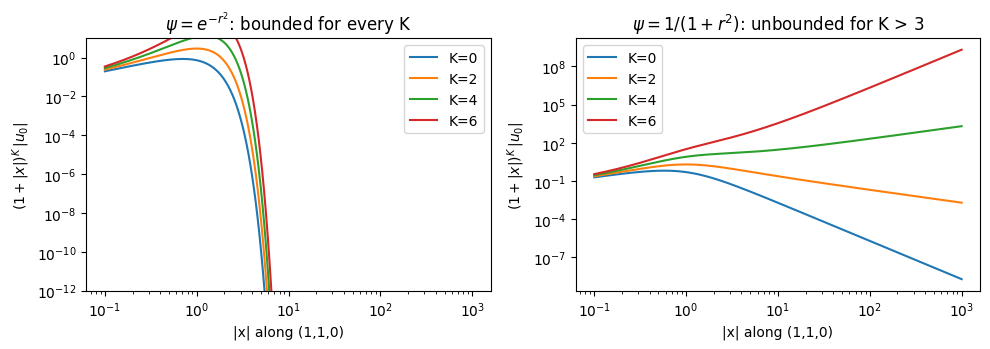

In [9]:
print("div(gaussian swirl) =", ns.divergence(ns.gaussian_swirl()),
      "  div(algebraic swirl) =", ns.divergence(ns.algebraic_swirl()))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for K in (0, 2, 4, 6):
    r, prof = ns.decay_profile(ns.gaussian_swirl(), K); ax[0].loglog(r, prof + 1e-300, label=f"K={K}")
    r, prof = ns.decay_profile(ns.algebraic_swirl(), K); ax[1].loglog(r, prof, label=f"K={K}")
ax[0].set_ylim(1e-12, 10); ax[0].set_title(r"$\psi=e^{-r^2}$: bounded for every K")
ax[1].set_title(r"$\psi=1/(1+r^2)$: unbounded for K > 3")
for a in ax: a.set_xlabel("|x| along (1,1,0)"); a.set_ylabel(r"$(1+|x|)^K\,|u_0|$"); a.legend()
plt.tight_layout(); plt.show()

# 5. The energy identity

Dot the PDE with $v$ and integrate over the torus. Because $v$ is periodic and divergence-free, the
convective term and the pressure term both integrate to zero:
$$\int v\cdot(v\cdot\nabla)v = \int (v\cdot\nabla)\tfrac{|v|^2}{2} = -\int (\nabla\cdot v)\tfrac{|v|^2}{2} = 0, \qquad \int v\cdot\nabla p = -\int p\,\nabla\cdot v = 0 .$$
What remains is
$$\frac{d}{dt}\,\frac12\int|v|^2 = -\nu\int|\nabla v|^2 + \int f\cdot v .$$
This is where `div_free` does its work. It is also the source of the bounded-energy field in
`NavierStokesExistenceAndSmoothnessRn`. SymPy checks both sides on the exact flows:

In [10]:
lhs, rhs = ns.energy_balance(ns.taylor_green()[0])
display(Math(r"\text{Taylor-Green: } \tfrac{dE}{dt} = " + sp.latex(lhs) + r",\quad -\nu\!\int|\nabla v|^2 = " + sp.latex(rhs)))
v, _, f = ns.abc_flow()
lhs, rhs = ns.energy_balance(v, f)
display(Math(r"\text{ABC (forced, steady): } \tfrac{dE}{dt} = " + sp.latex(lhs) + r",\quad -\nu\!\int|\nabla v|^2 + \int f\cdot v = " + sp.latex(rhs)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

# 6. Scaling symmetry and why 3D is "supercritical"

If $(v,p,f)$ solves NS, so does
$$v_\lambda = \lambda\,v(\lambda x, \lambda^2 t),\quad p_\lambda = \lambda^2 p(\lambda x,\lambda^2 t),\quad f_\lambda = \lambda^3 f(\lambda x,\lambda^2 t).$$
Every term in the equation picks up the same factor $\lambda^3$. Applied to Taylor–Green:

In [11]:
vl, pl, fl = ns.scaled_solution(*ns.taylor_green())
display(Math(r"v_\lambda = " + sp.latex(sp.simplify(vl.T))))
print("NS residual of the scaled flow:", list(ns.ns_residual(vl, pl, fl)))
for d in (2, 3):
    print(f"dim {d}: int |v_lambda|^2 dx = lambda^({ns.energy_scaling_exponent(d)}) int |v|^2 dx")

<IPython.core.display.Math object>

NS residual of the scaled flow: [0, 0, 0]
dim 2: int |v_lambda|^2 dx = lambda^(0) int |v|^2 dx
dim 3: int |v_lambda|^2 dx = lambda^(-1) int |v|^2 dx


**What the exponent means.** In 3D the energy scales as $\lambda^{-1}$. Zooming into a small region
($\lambda \to \infty$) makes the energy of the zoomed flow *smaller*. So a solution can concentrate at
small scales while staying within any fixed energy budget, and the one global bound we have (§5) gives
no control at small scales. In 2D the exponent is 0 and the energy *does* control small scales. This
mismatch is why the problem is called supercritical.

## 6.1 Vortex stretching vanishes in 2D

Taking the curl of NS gives $\partial_t\omega + (v\cdot\nabla)\omega = (\omega\cdot\nabla)v + \nu\Delta\omega$.
For a planar flow $v=(u(x,y),w(x,y),0)$, the vorticity points along $z$ and nothing depends on $z$,
so the stretching term is identically zero:

In [12]:
print("(omega . grad) v for a generic 2D flow =", list(ns.vortex_stretching_2d()))

(omega . grad) v for a generic 2D flow = [0, 0, 0]


With no stretching, $|\omega|$ obeys a maximum principle and 2D solutions stay smooth forever.
That is a theorem. In 3D, $(\omega\cdot\nabla)v$ can amplify vorticity, and every blowup scenario,
including whatever the repository constructs, has to run through it.

# 7. From the equations to cell imaging: which regime are we in?

In imaging flow cytometry, cells ride a liquid through a microchannel past a fast camera or a
time-stretch imager [5]. The Reynolds number $Re = UW/\nu$ decides which terms of NS matter. For
water, $\nu \approx 10^{-6}\ \mathrm{m^2/s}$:

In [13]:
rows = []
for U in (0.01, 0.1, 1.0, 4.0):
    for W in (30e-6, 100e-6):
        rows.append({"U (m/s)": U, "W (um)": W*1e6, "Re": round(ns.channel_reynolds(U, W), 3)})
pd.DataFrame(rows).pivot(index="U (m/s)", columns="W (um)", values="Re")

W (um),30.0,100.0
U (m/s),,
0.01,0.3,1.0
0.10,3.0,10.0
1.00,30.0,100.0
4.00,120.0,400.0


* $Re \ll 1$: **Stokes flow**. The convective term $(v\cdot\nabla)v$ drops out, the equation becomes
  linear, and cells follow streamlines exactly. Because the flow is reversible, nothing sorts the
  cells.
* $Re \sim 1$–$100$ (m/s speeds, tens of µm): **inertial microfluidics**. The nonlinear term creates
  lift forces that focus cells to fixed positions across the channel. High-throughput imagers rely on
  this, and it comes from the very term Lean writes as `fderiv (v · t) x (v x t)`.
* The channel never gets anywhere near blowup. These flows are smooth and well-posed. The open
  problem concerns arbitrarily large $Re$ at arbitrarily small scales in 3D.

For a tracking test we need a flow where the true velocity is known **everywhere**. Taylor–Green is
the natural choice: an exact NS solution with closed-form streamlines.

# 8. Synthetic cell tracking in a known Navier–Stokes flow

Pipeline (`track_and_compare`):

1. **Advect** 40 point "cells" with RK4 in the 2D Taylor–Green field ($\nu=0.01$, unit torus).
2. **Render** each frame at 128×128: one Gaussian spot per cell ($\sigma = 1.5$ px), plus white noise.
3. **Detect**: threshold, connected components, intensity-weighted centroids, with periodic
   wrap-around.
4. **Link** frame to frame by nearest neighbour (minimum-image distance, gate 0.02 = 2.6 px).
5. **Velocity** = displacement / time, compared with the exact field at the chord midpoint.

All numbers are in units of the domain (length 1) and the flow time.

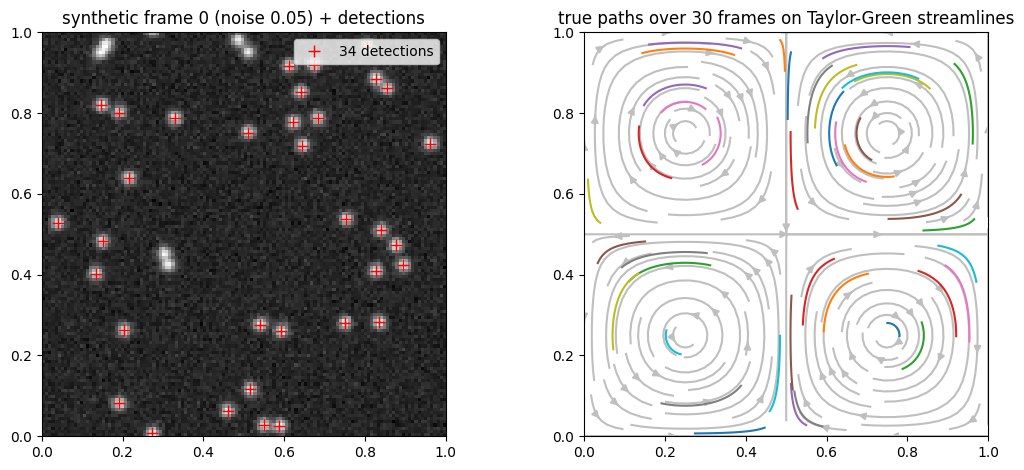

In [14]:
rng = np.random.default_rng(1)
start = rng.random((40, 2))
paths = ns.advect(start, 0.0, 0.01, 29)
img = ns.render_frame(paths[0], noise=0.05, rng=rng)
det = ns.detect_cells(img, max_area=18)

g = np.linspace(0, 1, 25); GX, GY = np.meshgrid(g, g)
U0, V0 = ns.tg2d_velocity(GX, GY, 0.0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
ax[0].imshow(img, origin="lower", extent=(0, 1, 0, 1), cmap="gray")
ax[0].plot(det[:, 0], det[:, 1], "r+", ms=8, label=f"{len(det)} detections")
ax[0].set_title("synthetic frame 0 (noise 0.05) + detections"); ax[0].legend(loc="upper right")
ax[1].streamplot(g, g, U0, V0, color="0.75", density=1.2)
for k in range(paths.shape[1]):
    seg = paths[:, k]; jump = np.r_[False, np.any(np.abs(np.diff(seg, axis=0)) > 0.5, axis=1)]
    seg = seg.copy(); seg[jump] = np.nan
    ax[1].plot(seg[:, 0], seg[:, 1], lw=1.5)
ax[1].set_xlim(0, 1); ax[1].set_ylim(0, 1); ax[1].set_aspect("equal")
ax[1].set_title("true paths over 30 frames on Taylor-Green streamlines")
plt.tight_layout(); plt.show()

## 8.1 Failure mode first: touching cells swap identities

When two spots touch, the threshold merges them into one blob. Its single centroid sits between the
two cells, and the nearest-neighbour linker can then hand a track to the wrong cell. That shows up as a
velocity error larger than the flow speed itself. The fix is physical: a single cell has a known size
(about 12 pixels above threshold here), so **reject blobs above 18 px**. Tracks that pass through a
merge end instead of jumping.

In [15]:
rows = []
for gate in (None, 18):
    for noise in (0.02, 0.05, 0.1):
        r = ns.track_and_compare(noise=noise, max_area=gate)
        rows.append({"area gate": gate or "none", "noise": noise, "tracks kept": r["n_tracked"],
                     "swap fraction": round(r["swap_fraction"], 3),
                     "rel. RMS error": round(r["rel_rms_error"], 3), "rel. median error": round(r["rel_median_error"], 3)})
pd.DataFrame(rows)

,area gate,noise,tracks kept,swap fraction,rel. RMS error,rel. median error
0,none,0.02,34,0.088,0.257,0.162
1,none,0.05,32,0.156,0.351,0.201
2,none,0.10,31,0.129,0.406,0.296
3,18,0.02,30,0.000,0.204,0.171
4,18,0.05,26,0.000,0.248,0.207
5,18,0.10,27,0.037,0.376,0.305


The gate removes the merge-driven swaps at low noise. It does not remove them all: at noise 0.10
some noise spikes cross the threshold and form spurious one-pixel "cells" that the linker can grab.
The cost of the gate is fewer complete tracks. Note that the median error barely moves: the RMS error
is dominated by a few catastrophic swaps, which is why both are reported.

## 8.2 Error budget: centroid noise vs curvature

With a 1-frame difference, a centroid error $\delta$ (a fraction of a pixel) becomes a velocity
error $\sim\sqrt2\,\delta/\Delta t$, which is large because a cell moves only about 1 px per frame.
Differencing over $s$ frames divides that by $s$. The cost is that a straight chord cuts across the
curved path, an error that grows like $s^2$. The best stride balances the two:

,stride,rel. RMS velocity error
0,1,0.2480
1,2,0.1255
2,4,0.0632
3,8,0.0331
4,12,0.0298


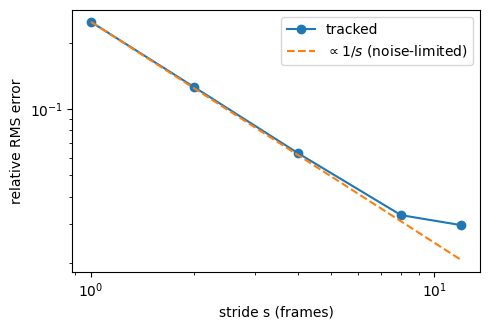

In [16]:
strides = (1, 2, 4, 8, 12)
res = [ns.track_and_compare(noise=0.05, max_area=18, stride=s) for s in strides]
err = [r["rel_rms_error"] for r in res]
display(pd.DataFrame({"stride": strides, "rel. RMS velocity error": np.round(err, 4)}))
plt.figure(figsize=(5, 3.4))
plt.loglog(strides, err, "o-", label="tracked")
plt.loglog(strides, err[0] / np.array(strides, float), "--", label=r"$\propto 1/s$ (noise-limited)")
plt.xlabel("stride s (frames)"); plt.ylabel("relative RMS error"); plt.legend(); plt.tight_layout(); plt.show()

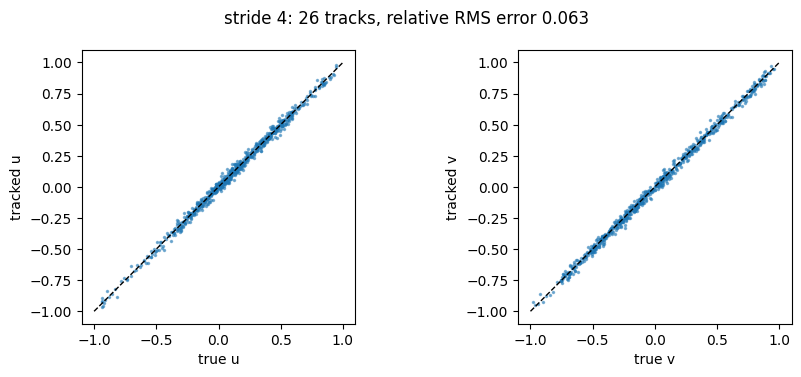

In [17]:
r = ns.track_and_compare(noise=0.05, max_area=18, stride=4)
vm, vt = r["v_meas"].reshape(-1, 2), r["v_true"].reshape(-1, 2)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for i, c in enumerate("uv"):
    ax[i].plot(vt[:, i], vm[:, i], ".", ms=3, alpha=0.5); ax[i].plot([-1, 1], [-1, 1], "k--", lw=1)
    ax[i].set_xlabel(f"true {c}"); ax[i].set_ylabel(f"tracked {c}"); ax[i].set_aspect("equal")
fig.suptitle(f"stride 4: {r['n_tracked']} tracks, relative RMS error {r['rel_rms_error']:.3f}")
plt.tight_layout(); plt.show()

# 9. Using `div_free` as a physics constraint (Leray projection)

Tracking or PIV gives a noisy velocity *field*. The Lean structure requires $\nabla\cdot v = 0$, and
for an incompressible liquid that is physics, not an assumption. So any divergence in the measurement
is noise, and we can remove it.

On the torus, every field splits uniquely into a divergence-free part plus a gradient (Helmholtz).
In Fourier space the **Leray projector** onto the divergence-free part is
$$\hat P(k) = I - \frac{k\,k^\top}{|k|^2}.$$
SymPy confirms that it is a projector and that it kills divergence:

In [18]:
kx, ky = sp.symbols("k_x k_y", real=True, nonzero=True)
kv = sp.Matrix([kx, ky]); P = sp.eye(2) - kv*kv.T/(kv.T*kv)[0]
print("P^2 - P =", sp.simplify(P*P - P))
print("k^T P   =", sp.simplify(kv.T*P))
print("trace P =", sp.simplify(P.trace()), " (rank 1 of 2 -> keeps half the degrees of freedom)")

P^2 - P = Matrix([[0, 0], [0, 0]])
k^T P   = Matrix([[0, 0]])
trace P = 1  (rank 1 of 2 -> keeps half the degrees of freedom)


**Prediction.** The true field is already divergence-free, so $P$ leaves it **unchanged**. White
noise is spread evenly over both polarizations at each wavevector, and $P$ removes one of the two. So
the RMS error should drop by a factor of $\sqrt{1/2}\approx0.707$, at no cost to the signal:

In [19]:
rows = []
for sd in range(5):
    d = ns.projection_denoise_demo(seed=sd)
    rows.append({k: d[k] for k in ("err_noisy", "err_projected", "ratio", "div_noisy_rms", "div_projected_rms", "signal_change")})
df = pd.DataFrame(rows); display(df.round(6))
print(f"mean ratio = {df.ratio.mean():.4f}   (prediction sqrt(1/2) = {np.sqrt(0.5):.4f})")

,err_noisy,err_projected,ratio,div_noisy_rms,div_projected_rms,signal_change
0,0.283065,0.198575,0.701517,32.275870,0.0,0.0
1,0.281796,0.198909,0.705860,31.855328,0.0,0.0
2,0.282376,0.200059,0.708483,31.920628,0.0,0.0
3,0.284045,0.201514,0.709444,32.029988,0.0,0.0
4,0.280633,0.197710,0.704516,32.013354,0.0,0.0


mean ratio = 0.7060   (prediction sqrt(1/2) = 0.7071)


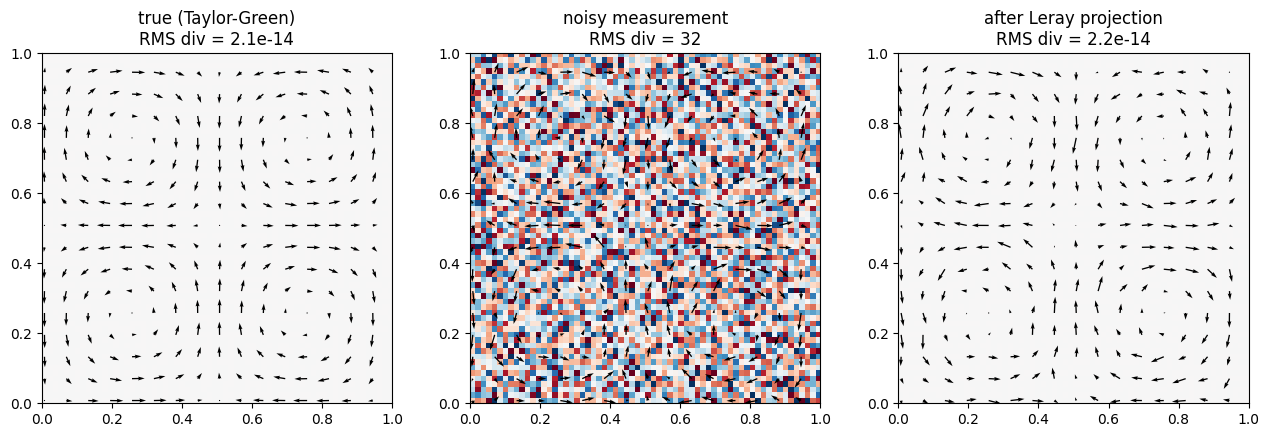

In [20]:
PX, PY, u0, v0, un, vn, up, vp = ns.projection_denoise_demo(seed=0)["fields"]
s = slice(None, None, 4)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for a, (u, v, title) in zip(ax, ((u0, v0, "true (Taylor-Green)"), (un, vn, "noisy measurement"), (up, vp, "after Leray projection"))):
    a.imshow(ns.spectral_divergence(u, v), origin="lower", extent=(0, 1, 0, 1), cmap="RdBu", vmin=-60, vmax=60)
    a.quiver(PX[s, s], PY[s, s], u[s, s], v[s, s], scale=25)
    a.set_title(title + f"\nRMS div = {np.sqrt(np.mean(ns.spectral_divergence(u, v)**2)):.2g}"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

This is the "physics–AI" pattern in its simplest form. A hard physical constraint (a definition
that Lean states exactly) is applied as a **projection**, not learned from data. It is guaranteed to
be harmless to any true incompressible flow and helpful against isotropic noise. In 3D, $P$ keeps
2 of 3 polarizations, so the expected ratio is $\sqrt{2/3}\approx0.816$.

The same projection appears in fluid solvers (Chorin's projection method [4]) and in physics-informed
neural networks. There, a divergence-free output layer (predict a stream function, take its curl)
enforces exactly the same Lean field by construction.

# 10. Checking the Lean proofs yourself

This is the only step that tests the repository's claim. It needs the Lean toolchain (`elan` and the
pinned compiler, about 1 GB) and the Mathlib build cache.

```bash
# install elan (Lean version manager): https://github.com/leanprover/elan
cd NavierStokesAndEuler
lake exe cache get      # download prebuilt Mathlib .olean files
lake build              # compile; kernel checks every proof
```

### Result of the build (run 2026-10-04)

| Item | Result |
|---|---|
| toolchain | Lean 4.34.0-rc2 (pinned by `lean-toolchain`), Lake 5.0.0 |
| `lake build` | **11,424 jobs, 0 errors**, "Build completed successfully" |
| `navier_stokes_breakdown_R3` (Clay alternative C) | depends on axioms `[propext, Classical.choice, Quot.sound]` |
| `navier_stokes_breakdown_periodic` (Clay alternative D) | `[propext, Classical.choice, Quot.sound]` |
| `euler_breakdown_R3`, `exists_compact_smooth_euler_singularity` | `[propext, Classical.choice, Quot.sound]` |
| solution definitions vs challenge definitions | 64 / 64 lines, **0 differences** (comments and namespaces ignored) |

Those three are Lean's standard axioms, on which Mathlib itself rests. `sorryAx` does not appear, so
no step was skipped.

**Two practical lessons from running it on Windows:**
* **Don't build on an exFAT drive.** With 1 MB clusters, Mathlib's ~45,000 small files took ~49 GB on
  disk. The build was moved to an NTFS drive, where it used about 37 GB.
* **Limit parallelism.** By default Lake ran one Lean process per logical core (28) and exhausted
  Windows' commit memory, failing with `0xC000012D` and "failed to read file …olean". Setting
  `LEAN_NUM_THREADS=6` fixed it.

| Established by the build | Not established |
|---|---|
| every proof step type-checks in Lean's kernel | that the Lean statements match Clay's English statement (human review of §1–§7) |
| no `sorry` or extra axioms | anything about physical fluids beyond the mathematical model |
| the theorems as stated in Lean are true, given Mathlib's foundations | acceptance by the mathematical community or the Clay Institute |

The cell below **re-checks the axioms live**. It re-elaborates `ComparatorSolution.lean` against
the built cache, which takes about 20 s, and compares the definitions files. If Lean or a completed
build isn't found, it says so and checks nothing.

In [21]:
match = ns.definitions_match()
if match is not None:
    n_a, n_b, diff = match
    print(f"definitions: challenge {n_a} lines, solution {n_b} lines, differing lines: {len(diff)}")
    for d in diff[:10]:
        print("   ", d)
build = ns.lean_build_dir()
print("completed build found at:", build)
axioms = ns.lean_axioms() if build is not None else None
if axioms is None:
    print("Lean toolchain or completed build not found -- the proofs were NOT re-checked by this run.")
else:
    for thm, ax in axioms.items():
        ok = set(ax) <= ns.STANDARD_AXIOMS
        print(f"{thm}\n    axioms: {ax}  ->  {'standard axioms only' if ok else 'NON-STANDARD AXIOM PRESENT'}")

definitions: challenge 64 lines, solution 64 lines, differing lines: 0
completed build found at: C:\Users\mrjel\lean\NavierStokesAndEuler


NavierStokes.Comparator.navier_stokes_breakdown_R3
    axioms: ['propext', 'Classical.choice', 'Quot.sound']  ->  standard axioms only
NavierStokes.Comparator.navier_stokes_breakdown_periodic
    axioms: ['propext', 'Classical.choice', 'Quot.sound']  ->  standard axioms only


# Summary

| Lean object | SymPy / NumPy counterpart | Result here |
|---|---|---|
| `divergence := (fderiv v x).trace` | `trace(jacobian(v))` | matches textbook; basis-independent |
| `divergence_zero/const/add/smul` | `divergence_lemmas()` | all residuals 0 (smooth fields only) |
| `fderiv (v · t) x (v x t)` | `convective(v) = J v` | equals $(v\cdot\nabla)v$ |
| `navier_stokes`, `div_free`, `IsOnePeriodic` | `ns_residual`, `divergence`, `is_one_periodic` | Taylor–Green and ABC satisfy all |
| `InitialVelocityConditionDecay` | `decay_profile` | Gaussian swirl passes, $1/(1+r^2)$ swirl fails |
| `globally_bounded_energy` | `energy_balance` | energy identity verified on both flows |
| (scaling; not in the file) | `scaled_solution`, `energy_scaling_exponent` | $\lambda^{2-d}$: supercritical in 3D |
| `div_free` as a constraint | `leray_project` | removes divergence to $10^{-14}$; noise $\times 0.70$ |
| `navier_stokes_breakdown_R3/periodic` | `lean_axioms`, `definitions_match` | **built and kernel-checked** (2026-10-04): standard axioms only; definitions identical to the challenge |

## Exercises
1. Change `divergence_smul` to use a *non-constant* scalar $c(x)$. Find the extra term SymPy reports. Why does Lean state the lemma only for constant $c$?
2. Show by hand that $v_\lambda$ solves NS: compute the power of $\lambda$ on $\partial_t v_\lambda$, $(v_\lambda\cdot\nabla)v_\lambda$, $\nu\Delta v_\lambda$.
3. Repeat §9 in 3D with an ABC field and confirm the error ratio $\sqrt{2/3}$.
4. In §8, add a 4th source of error, a constant camera drift, and show that it survives the Leray projection. (Hint: a uniform flow is divergence-free.)
5. Using the Lean source, list every hypothesis of `NavierStokesExistenceAndSmoothnessRn`. Which one would a numerical solver check *least* reliably?